# Post-drought forest dieback in Sardinia: where should foresters inspect first?

**Earth Observation AI Engineer · home assignment**

In summer 2024 southern and eastern Sardinia went through an extreme drought and heatwave. The Regional Government reported a fast-spreading dieback of cork-oak and holm-oak woods and Mediterranean scrub over thousands of hectares, monitored with satellite imagery, drones and field checks in Gallura, Nuorese, Ogliastra, Baronia and Sarrabus (Delibera RAS n. 31/7, 28 Aug 2024).

This notebook turns Sentinel-2 imagery into a ranked list of forest areas to inspect in the Sette Fratelli massif (Sarrabus, SE Sardinia).

## 1. Decision question and user

- **User:** the regional forest service (Agenzia Forestas / Corpo Forestale), planning field surveys after the drought.
- **Decision:** *Which forest areas should field teams inspect first for dieback, i.e. canopy that dried out in 2024 **and did not recover** in 2025?*
- **Why recovery matters:** in a drought year almost every Mediterranean evergreen canopy loses water and some leaves, then recovers. An alert on the 2024 drop alone would flag almost the whole forest. Persistent decline (no recovery the following year) is the signal linked to dieback and later mortality (Lloret et al., 2011; DeSoto et al., 2020), and is the same resistance → recovery logic used with Sentinel-2 after the 2018 drought in Switzerland (Sturm et al., 2022).

## Method at a glance

![Method flow](figures/method_flow.jpg)

*Illustrative render with labels, not to scale. Each step is a function in `src/pipeline.py` and a section of this notebook: 1–2 → sections 3–4, 3 → sections 5–6, 4 → section 6, 5 → section 7.*

![Healthy, dried, partly recovered forest](figures/illustration_recovery_triptych.jpg)

*Illustrative render, not to scale. The same forest before the drought, in summer 2024, and in summer 2025. The drought browns almost every crown (centre). What the forest service needs to find are the stands that **stay** grey-brown a year later (right). Not the drop, but the missing recovery, is the alert.*

In one paragraph: we download every clear Sentinel-2 acquisition of seven summers, measure canopy water (NDMI) on each, and build one median image per summer. We remove fires and clear-cuts, compare each pixel with its own 2019–2023 normal *relative to the surrounding forest*, and flag pixels that dropped unusually in 2024 **and** regained less than half of it in 2025. Flags are aggregated into 25 ha cells and ranked: that ranking is the inspection list.

## 2. Data and backend choices

| Choice | Decision | Why |
|---|---|---|
| Backend | **Microsoft Planetary Computer** (STAC API) | No account needed: anyone can rerun the notebook. Real pixels are read from Cloud-Optimised GeoTIFFs (only the AOI window is downloaded). ESA WorldCover is in the same catalogue. |
| Collection | **Sentinel-2 L2A** | 10–20 m, 5-day revisit, surface reflectance (atmospherically corrected), SWIR bands B11/B12 needed for canopy water. Landsat is coarser (30 m) and less frequent; Sentinel-1 does not measure leaf water directly. |
| Season | **July–September** of each year, 2019–2025 | Peak of the dry season, when drought stress is visible; same phenological window every year so years are comparable; very few clouds in Sardinian summers. |
| Baseline | **2019–2023** summers | Five pre-event summers, including a dry (2021) and a wet (2022) one, to estimate normal inter-annual variability. |
| Forest mask | **ESA WorldCover 2021**, class 10 (tree cover) | Open, 10 m, global, same catalogue. |

All processing code lives in `src/pipeline.py`. The notebook and the MCP server (bonus A) call the same functions.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import pipeline as pl

# Area of interest: Sette Fratelli massif, Sarrabus (lon_min, lat_min, lon_max, lat_max)
AOI = (9.33, 39.19, 9.52, 39.33)
YEARS = list(range(2019, 2026))
BASE_YEARS = [2019, 2020, 2021, 2022, 2023]
SEASON = ("07-01", "09-30")
RES = 20  # metres; native resolution of B8A/B11/B12

In [2]:
import folium

lon0, lat0, lon1, lat1 = AOI
m = folium.Map(location=[(lat0 + lat1) / 2, (lon0 + lon1) / 2], zoom_start=10, tiles="OpenStreetMap")
folium.Rectangle([[lat0, lon0], [lat1, lon1]], color="red", fill=False, tooltip="AOI").add_to(m)
m

## 3. Ingest: real Sentinel-2 L2A acquisitions

We query the STAC catalogue for every summer and keep scenes with tile-level cloud cover below 20 %.

Some acquisition dates appear twice: ESA reprocessed them with a newer *processing baseline*. We keep one item per date, the most recent baseline (`pl.dedup_by_date`).

In [3]:
# pl.search_scenes: STAC query on Planetary Computer for Sentinel-2 L2A scenes over the AOI in the
# date window, pre-filtered on tile-level cloud cover < 20 %, one item per date (newest baseline)
scenes = {y: pl.search_scenes(AOI, f"{y}-{SEASON[0]}", f"{y}-{SEASON[1]}") for y in YEARS}
summary = pd.DataFrame({
    "acquisitions": {y: len(v) for y, v in scenes.items()},
    "tiles": {y: ", ".join(sorted({it.properties["s2:mgrs_tile"] for it in v})) for y, v in scenes.items()},
})
summary.loc["total"] = [summary.acquisitions.sum(), ""]
summary

,acquisitions,tiles
2019,13,32SNJ
2020,15,32SNJ
2021,9,32SNJ
2022,13,32SNJ
2023,15,32SNJ
2024,12,32SNJ
2025,21,32SNJ
total,98,


In [4]:
# pl.scenes_table: one row per acquisition (date, tile, cloud cover, processing baseline, id)
pl.scenes_table(scenes[2024])

,date,tile,cloud_cover_%,baseline,id
0,2024-07-11,32SNJ,0.0,05.10,S2B_MSIL2A_20240711T100559_R022_T32SNJ_2024071...
1,2024-07-16,32SNJ,0.0,05.10,S2A_MSIL2A_20240716T100601_R022_T32SNJ_2024071...
2,2024-07-21,32SNJ,0.3,05.10,S2B_MSIL2A_20240721T100559_R022_T32SNJ_2024072...
3,2024-07-26,32SNJ,0.2,05.11,S2A_MSIL2A_20240726T100601_R022_T32SNJ_2024072...
4,2024-07-31,32SNJ,0.0,05.11,S2B_MSIL2A_20240731T100559_R022_T32SNJ_2024073...
5,2024-08-05,32SNJ,4.7,05.11,S2A_MSIL2A_20240805T100601_R022_T32SNJ_2024080...
6,2024-08-10,32SNJ,1.6,05.11,S2B_MSIL2A_20240810T100559_R022_T32SNJ_2024081...
7,2024-08-25,32SNJ,0.0,05.11,S2A_MSIL2A_20240825T100551_R022_T32SNJ_2024082...
8,2024-08-30,32SNJ,0.1,05.11,S2B_MSIL2A_20240830T100559_R022_T32SNJ_2024083...
9,2024-09-09,32SNJ,5.8,05.11,S2B_MSIL2A_20240909T100559_R022_T32SNJ_2024090...


## 4. Preprocessing

1. **Scaling and offset.** L2A digital numbers are reflectance × 10 000. Since processing baseline 04.00 (25 Jan 2022) a +1000 offset is added. We remove it before any index: normalised-difference indices are *not* invariant to an additive offset, so mixing baselines without correction would create a fake 2022 break in the time series.
2. **Cloud / quality masking with the Scene Classification Layer (SCL).** We keep only *vegetation* (4) and *not-vegetated* (5) pixels. Clouds (8, 9), cirrus (10), cloud shadows (3), water (6), snow (11), saturated/defective and no-data pixels are dropped. Using a whitelist rather than a blacklist is conservative: unknown or unclassified pixels (7) are excluded too.
3. **Resolution and CRS.** Everything is resampled on one 20 m grid in UTM 32N (EPSG:32632), the native CRS of the tile, so no reprojection of the original pixels is needed. 20 m is the native resolution of B8A/B11/B12, which drive the moisture indices.
4. **Temporal handling.** One median composite per summer (July–September). The median is robust to residual clouds and haze missed by SCL and to single anomalous dates. One value per year also matches the question: how did this summer compare with normal summers?

Below, one 2024 acquisition before and after masking.

![Temporal compositing](figures/illustration_compositing_stack.jpg)

*Illustrative render, not to scale. Each summer contributes 9–21 acquisitions, many with clouds or shadows over part of the AOI. After masking, the per-pixel median over the season collapses them into one clean image per year.*

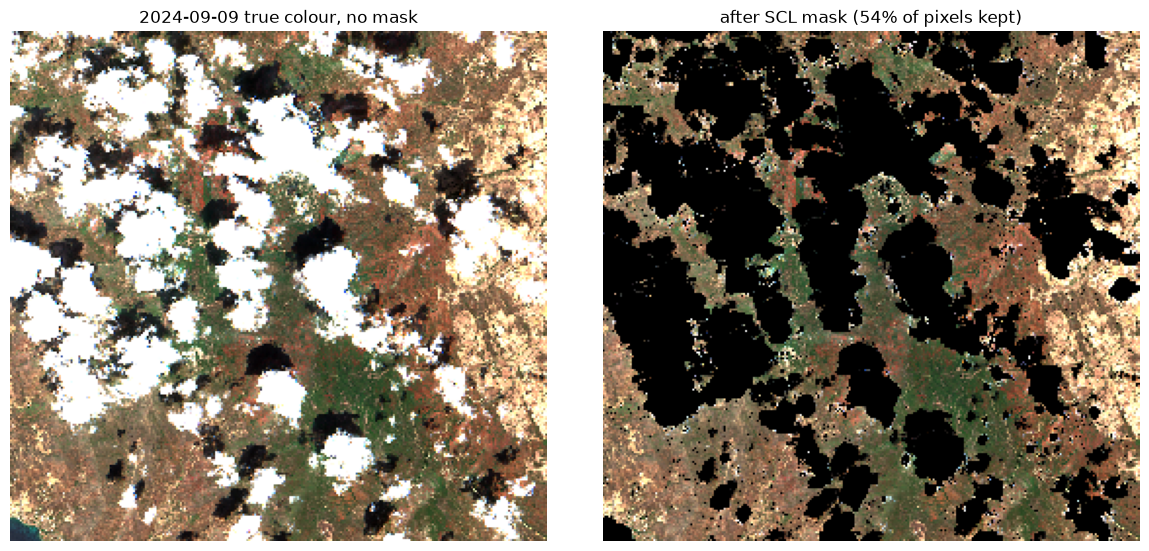

In [5]:
item = max(scenes[2024], key=lambda it: it.properties["eo:cloud_cover"])  # cloudiest 2024 scene, to show the mask
# pl.load_reflectance: reads only the AOI window of each band from the COGs, reprojects to one
# UTM 32N grid, converts DN to reflectance (removing the +1000 offset of baseline >= 04.00) and,
# with mask=True, sets to NaN every pixel whose SCL class is not vegetation (4) or not-vegetated (5)
raw = pl.load_reflectance([item], AOI, resolution=60, mask=False).isel(time=0).compute()
msk = pl.load_reflectance([item], AOI, resolution=60, mask=True).isel(time=0).compute()

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
# pl.to_rgb: stacks B04-B03-B02 into an RGB array, brightened and clipped to 0-1 for display
ax[0].imshow(pl.to_rgb(raw)); ax[0].set_title(f"{item.datetime.date()} true colour, no mask")
ax[1].imshow(pl.to_rgb(msk.fillna(0))); ax[1].set_title(f"after SCL mask ({float(msk.valid.mean()):.0%} of pixels kept)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

The scene's tile-level metadata says 5.8 % cloud cover, yet over our AOI the SCL mask removes about half of the pixels (clouds **and** their shadows). Two consequences:

- `eo:cloud_cover` is only a coarse pre-filter. Masking has to be per pixel.
- A seasonal **median** is needed: on any single date part of the forest is missing, but across the 12 summer dates of 2024 almost every pixel has several clear observations.

Even in this partly cloudy image, the September 2024 canopy already looks brown-red in many stands, the visual signature we will quantify with the indices.

## 5. Spectral indices, per acquisition

We compute four indices on every acquisition, after masking:

| Index | Formula (S2 bands) | What it measures | Role here |
|---|---|---|---|
| **NDMI** | (B8A − B11) / (B8A + B11) | Canopy water content: B11 (1.6 µm) is absorbed by leaf water, B8A (NIR) is not | **Main indicator.** Water loss comes first in drought, before visible browning |
| **NDVI** | (B08 − B04) / (B08 + B04) | Greenness / chlorophyll and leaf area | Secondary. In evergreen oaks it reacts later and less than NDMI |
| **CRswir** | B11 / [B8A + (1610−865)·(B12−B8A)/(2190−865)] | B11 reflectance divided by the continuum line between B8A and B12 at 1610 nm: isolates the water absorption at 1.6 µm from the general slope of the spectrum. Higher = drier | Expert cross-check, from operational oak-dieback mapping in France (Mouret et al., 2024) |
| **NBR** | (B8A − B12) / (B8A + B12) | Very sensitive to charred or removed canopy | Screening of fires and clear-cuts only |

For each summer we keep two products: the per-acquisition forest median (time series) and a per-pixel median composite (maps).

The next cell downloads about 100 scenes over the AOI window. It takes a few minutes.

![Continuum removal in the SWIR](figures/method_crswir.png)

*Synthetic spectra, illustrative values. NDMI and CRswir read the same physics: leaf water absorbs at 1.6 µm (B11). CRswir measures the depth of that absorption against the straight line (continuum) between B8A and B12. In healthy canopy B11 sits below the line; when leaves dry out it rises above it.*

In [6]:
# pl.summer_composites: for every summer, searches the scenes, loads masked reflectance, computes
# NDVI/NDMI/NBR/CRswir on each acquisition, then returns
#   comp     - per-pixel median composite of each index, one layer per year
#   forest   - ESA WorldCover 2021 tree-cover mask on the same 20 m grid
#   per_date - per-acquisition forest median of each index + share of forest that was cloud-free
comp, forest, per_date = pl.summer_composites(AOI, YEARS, SEASON, RES)
print(f"forest pixels: {int(forest.sum()):,} of {forest.size:,} ({float(forest.mean()):.1%}), "
      f"{float(forest.sum()) * RES**2 / 1e4:,.0f} ha")
print(f"acquisitions: {len(per_date)}, reliable (>=50% of forest cloud-free): {int(per_date.reliable.sum())}")
per_date.round(3).head(8)

forest pixels: 426,683 of 644,368 (66.2%), 17,067 ha
acquisitions: 98, reliable (>=50% of forest cloud-free): 90


,date,year,forest_valid_frac,ndvi,ndmi,nbr,crswir,reliable
0,2019-07-03 10:10:31.024,2019,1.000,0.762,0.289,0.566,0.929,True
1,2019-07-13 10:10:31.024,2019,1.000,0.739,0.272,0.547,0.950,True
2,2019-07-18 10:10:39.024,2019,0.691,0.741,0.277,0.547,0.939,True
3,2019-07-23 10:10:31.024,2019,1.000,0.752,0.272,0.556,0.956,True
4,2019-07-28 10:10:29.024,2019,0.529,0.716,0.292,0.548,0.896,True
5,2019-08-02 10:10:31.024,2019,0.523,0.569,0.245,0.494,0.968,True
6,2019-08-07 10:10:29.024,2019,1.000,0.747,0.267,0.543,0.957,True
7,2019-08-12 10:10:31.024,2019,1.000,0.735,0.258,0.539,0.973,True


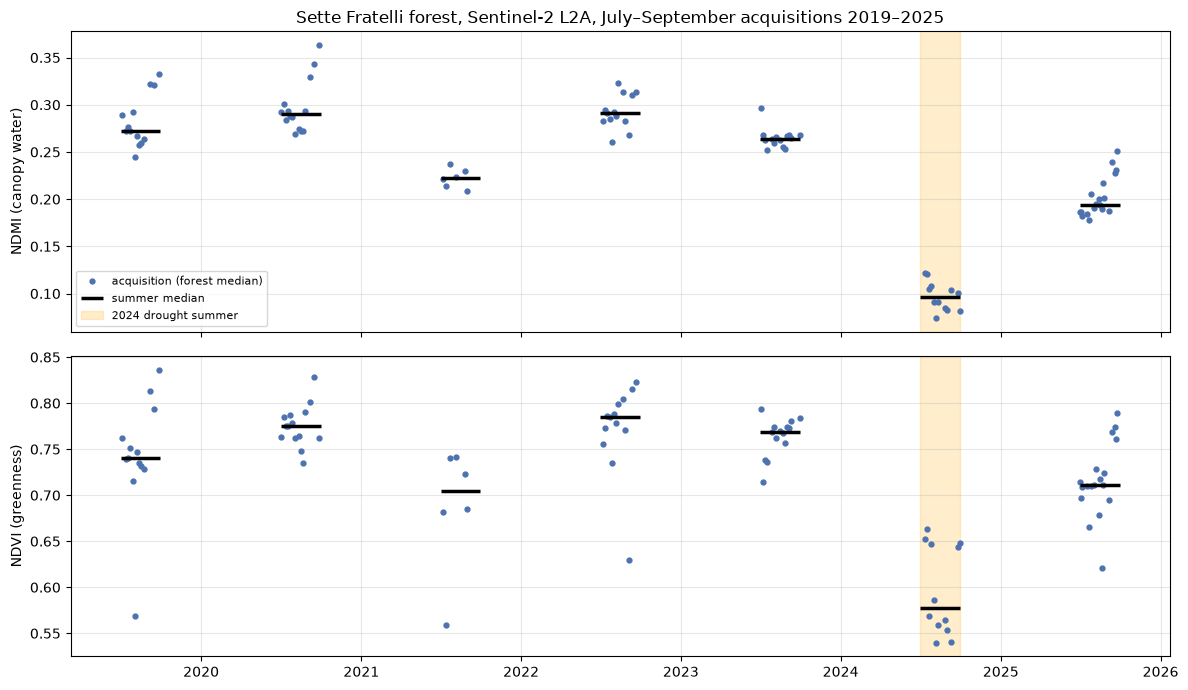

year,2019,2020,2021,2022,2023,2024,2025
ndmi,0.272,0.290,0.222,0.291,0.264,0.096,0.194
ndvi,0.741,0.775,0.704,0.785,0.769,0.577,0.711


In [7]:
import os
os.makedirs("outputs", exist_ok=True)

ok = per_date[per_date.reliable]
yearly = per_date[per_date.reliable].groupby("year")[["ndmi", "ndvi"]].median()

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for a, v, label in [(ax[0], "ndmi", "NDMI (canopy water)"), (ax[1], "ndvi", "NDVI (greenness)")]:
    a.plot(ok.date, ok[v], "o", ms=3.5, color="#4C72B0", label="acquisition (forest median)")
    for y, val in yearly[v].items():
        a.hlines(val, pd.Timestamp(f"{y}-{SEASON[0]}"), pd.Timestamp(f"{y}-{SEASON[1]}"), color="k", lw=2.5,
                 label="summer median" if y == YEARS[0] else None)
    a.axvspan(pd.Timestamp("2024-07-01"), pd.Timestamp("2024-09-30"), color="orange", alpha=0.2, label="2024 drought summer")
    a.set_ylabel(label); a.grid(alpha=0.3)
ax[0].legend(loc="lower left", fontsize=8)
ax[0].set_title("Sette Fratelli forest, Sentinel-2 L2A, July–September acquisitions 2019–2025")
plt.tight_layout(); plt.savefig("outputs/timeseries_ndmi_ndvi.png", dpi=120); plt.show()
yearly.round(3).T

Summer 2024 is far outside the range of the five previous summers in both indices, and the drop is larger in NDMI (water) than in NDVI (greenness), as expected for evergreen sclerophyllous oaks: they lose leaf water and turgor before they lose leaves. In 2025 the forest-wide medians come back up but stay below the 2019–2023 level.

Below are the summer composites in true colour (what an observer sees) and in false colour SWIR–NIR–red (B12, B8A, B04). In false colour, vigorous canopy is bright green (high NIR, low SWIR), stressed canopy turns dull grey-green to violet as SWIR reflectance rises and NIR falls, and bare soil and harvested fields are pink-violet. The 2024 composite is visibly duller over most of the massif, and in 2025 the bright green comes back over most of it but not everywhere.

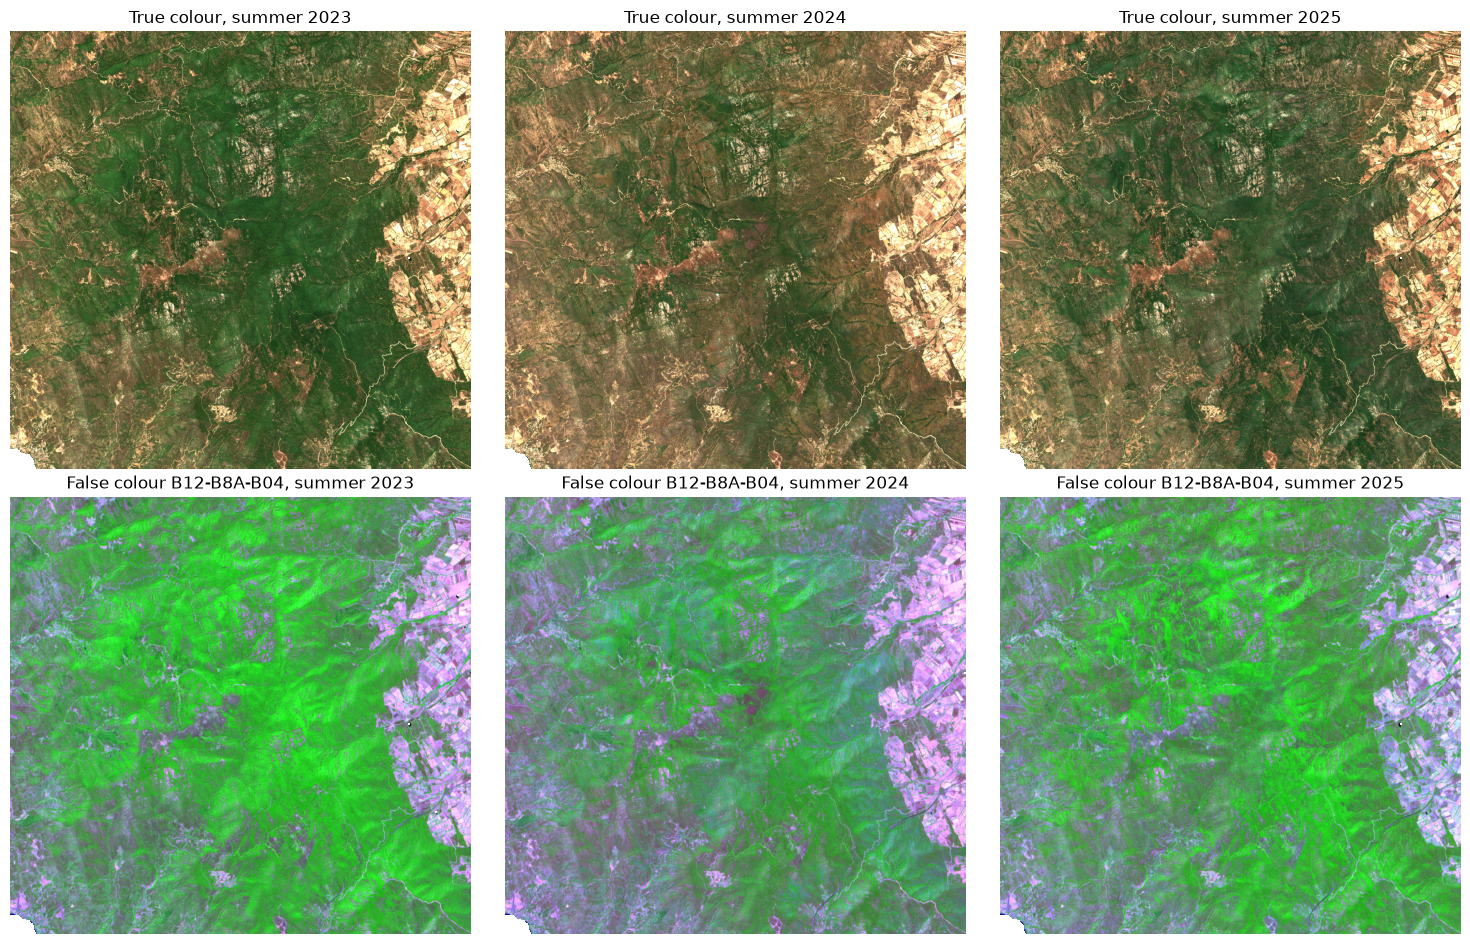

In [8]:
from src.pipeline import load_reflectance, search_scenes

def composite_bands(year, bands):
    # same search + masked reflectance as above, but keeping the raw bands for display
    items = search_scenes(AOI, f"{year}-{SEASON[0]}", f"{year}-{SEASON[1]}")
    r = load_reflectance(items, AOI, RES)
    return r[bands].median("time").compute()

def stretch(ds, bands, gains):
    return np.clip(np.stack([ds[b].values * g for b, g in zip(bands, gains)], -1), 0, 1)

show_years = [2023, 2024, 2025]
fig, ax = plt.subplots(2, 3, figsize=(15, 9.5))
for j, y in enumerate(show_years):
    c = composite_bands(y, ["B04", "B03", "B02", "B12", "B8A"])
    ax[0, j].imshow(stretch(c, ["B04", "B03", "B02"], [1 / 0.15] * 3)); ax[0, j].set_title(f"True colour, summer {y}")
    ax[1, j].imshow(stretch(c, ["B12", "B8A", "B04"], [1 / 0.35, 1 / 0.45, 1 / 0.15])); ax[1, j].set_title(f"False colour B12-B8A-B04, summer {y}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("outputs/composites_true_false_colour_2023_2025.png", dpi=110); plt.show()

## 6. From indices to a dieback signal: anomaly and recovery

### 6.1 Remove abrupt disturbances first
A fire or a clear-cut also produces "dried and not recovered" canopy, but it is not dieback and calls for a different response. Drought lowers NBR **gradually**; fire and logging make it **jump**. We flag pixels where NBR drops by more than 0.25 between two consecutive valid acquisitions (June–October 2024 and 2025) and does not come back up within the season, and we exclude them from the dieback analysis.

In [9]:
# pl.abrupt_disturbance: per-acquisition NBR for June-October of each year; flags pixels where NBR
# drops by > 0.25 between consecutive clear observations and stays > 0.15 below the pre-drop value
# for the rest of the season (step change = fire or logging, not gradual drought)
disturbed = pl.abrupt_disturbance(AOI, [2024, 2025], comp.isel(year=0), resolution=RES)
valid = forest & ~disturbed
print(f"forest pixels with an abrupt NBR drop (excluded): {int((disturbed & forest).sum()):,} "
      f"({float((disturbed & forest).sum() / forest.sum()):.1%} of forest)")

forest pixels with an abrupt NBR drop (excluded): 10,055 (2.4% of forest)


### 6.2 Anomaly in 2024, recovery in 2025

For each forest pixel and index:

1. **Landscape-relative value.** For each year we subtract the median of all forest pixels. This removes the climate signal shared by the whole AOI (every stand was drier in 2024 and the region had not fully recovered in 2025). What remains is *how much worse than the surrounding forest* a stand behaves, which is what tells a forester where to go.
2. **Anomaly in 2024:** $z = (x_{2024} - \mu) / \sigma$, with $\mu$ and $\sigma$ the median and standard deviation over the 2019–2023 summers. Each pixel is compared with its own normal variability.
3. **Recovery in 2025:** $R = (x_{2025} - x_{2024}) / (\mu - x_{2024})$, the fraction of the 2024 drop regained one year later. $R = 1$ means back to normal, $R = 0$ no recovery, $R < 0$ further decline.

This is the resistance / recovery logic of Lloret et al. (2011), applied to a spectral index as in Sturm et al. (2022) for the 2018 drought in Switzerland. Trees that recover poorly from a drought are the ones that die in the following years (DeSoto et al., 2020).

![Absolute vs landscape-relative](figures/method_landscape_relative.png)

*Synthetic data. In absolute values every stand looks alarming in 2024. After subtracting the forest-wide median of each year, only the stand that did worse than its surroundings and did not recover stands out.*

![Recovery logic](figures/method_recovery_logic.png)

*Synthetic data. Four possible 2025 outcomes for a pixel that dropped below μ − 2σ in 2024, with the recovery fraction R computed for each. Only R < 0.5 triggers an alert.*

In [10]:
Z_THR, R_THR = -2.0, 0.5
# pl.anomaly_recovery: subtracts the forest-wide median of each year (landscape=True), then per pixel
#   z   = (x_2024 - median_2019-23) / std_2019-23   -> how unusual 2024 was for that pixel
#   rec = (x_2025 - x_2024) / (median_2019-23 - x_2024) -> share of the 2024 drop regained in 2025
z, rec = pl.anomaly_recovery(comp, "ndmi", valid, BASE_YEARS, 2024, 2025, sign=1, landscape=True)
flag = (z <= Z_THR) & (rec < R_THR) & valid

# expert cross-check with the continuum-removed SWIR index (higher = drier, so sign=-1)
# same computation on CRswir; sign=-1 flips it so that low values mean drier, as for NDMI
z_cr, rec_cr = pl.anomaly_recovery(comp, "crswir", valid, BASE_YEARS, 2024, 2025, sign=-1, landscape=True)
flag_cr = (z_cr <= Z_THR) & (rec_cr < R_THR) & valid
jac = float((flag & flag_cr).sum() / (flag | flag_cr).sum())

ha = lambda m: float(m.sum()) * RES**2 / 1e4
print(f"NDMI flag: {ha(flag):,.0f} ha = {float(flag.sum() / valid.sum()):.1%} of analysed forest")
print(f"CRswir flag: {ha(flag_cr):,.0f} ha; agreement with NDMI (Jaccard): {jac:.2f}")

NDMI flag: 2,211 ha = 13.3% of analysed forest
CRswir flag: 2,241 ha; agreement with NDMI (Jaccard): 0.81


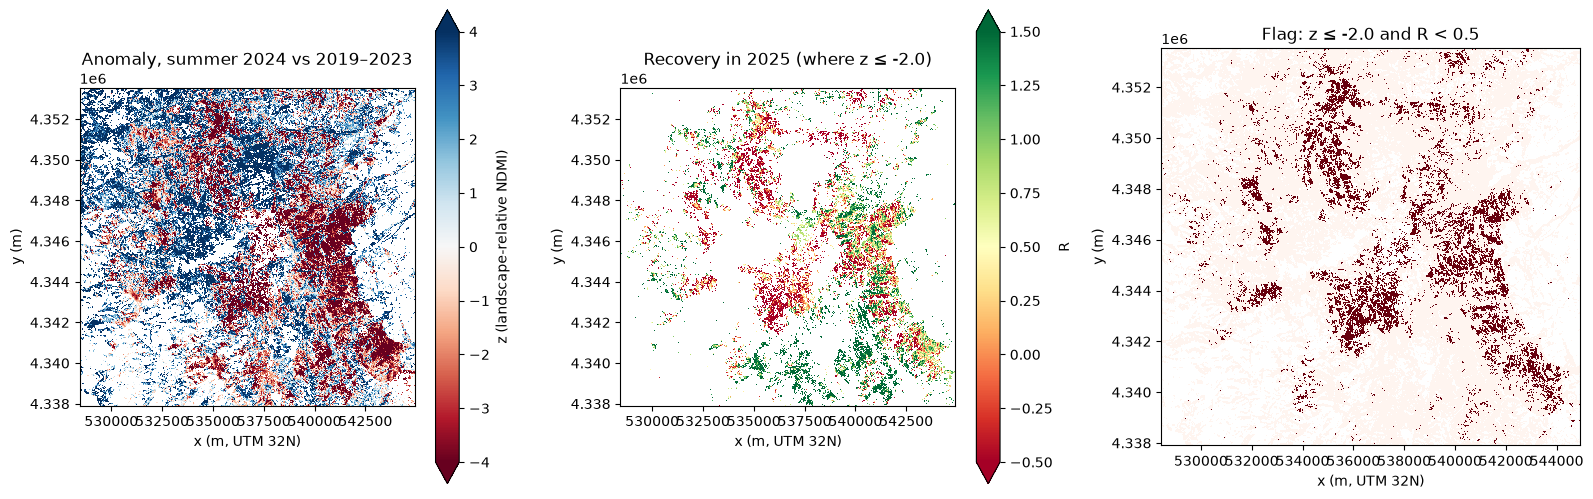

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
z.plot(ax=ax[0], cmap="RdBu", vmin=-4, vmax=4, cbar_kwargs={"label": "z (landscape-relative NDMI)"})
ax[0].set_title("Anomaly, summer 2024 vs 2019–2023")
rec.where(z <= Z_THR).plot(ax=ax[1], cmap="RdYlGn", vmin=-0.5, vmax=1.5, cbar_kwargs={"label": "R"})
ax[1].set_title(f"Recovery in 2025 (where z ≤ {Z_THR})")
flag.where(forest).plot(ax=ax[2], cmap="Reds", add_colorbar=False)
ax[2].set_title(f"Flag: z ≤ {Z_THR} and R < {R_THR}")
for a in ax: a.set_aspect("equal"); a.set_xlabel("x (m, UTM 32N)"); a.set_ylabel("y (m)")
plt.tight_layout(); plt.savefig("outputs/anomaly_recovery_flag.png", dpi=110); plt.show()

### 6.3 How sensitive is the result to the thresholds?

$z \le -2$ means "beyond two standard deviations of the pixel's own normal years", a conventional cut for an unusual event. $R < 0.5$ means "regained less than half of what was lost". Neither number is sacred, so we check how the flagged area changes around them.

In [12]:
rows = []
for zt in (-1.5, -2.0, -2.5):
    for rt in (0.25, 0.5, 0.75):
        f = (z <= zt) & (rec < rt) & valid
        rows.append({"z ≤": zt, "R <": rt, "flagged ha": round(ha(f)), "% of forest": round(100 * float(f.sum() / valid.sum()), 1)})
sens = pd.DataFrame(rows).pivot(index="z ≤", columns="R <", values="flagged ha")
sens

R <,0.25,0.50,0.75
z ≤,,,
-2.5,1663,1985,2301
-2.0,1865,2211,2553
-1.5,2082,2452,2820


## 7. Decision intelligence: where to inspect first

**Rule.** A forest pixel is a *dieback alert* when its landscape-relative NDMI was at least 2 standard deviations below normal in summer 2024 **and** it had regained less than half of that drop by summer 2025, excluding abrupt disturbances (fire, logging).

**Aggregation.** Field teams do not visit pixels. We aggregate on a 500 m grid (25 ha cells, about the scale of a forest compartment) and rank cells by flagged hectares. Cells with less than 50 % analysable forest are skipped.

In [13]:
# pl.cell_stats: tiles the AOI into 500 m squares (25 ha), skips cells with < 50 % analysable forest,
# and for each cell counts forest and flagged hectares, the median z and the median recovery of the
# flagged pixels; returns a GeoDataFrame ranked by flagged hectares, with centroid lat/lon
cells = pl.cell_stats(flag, valid, z, rec, cell=500, resolution=RES)
priority = cells[cells.flagged_frac >= 0.5]
print(f"{len(cells)} cells analysed; {len(priority)} with at least half of their forest flagged")
cols = ["rank", "lat", "lon", "forest_ha", "flagged_ha", "flagged_frac", "z2024_median", "recovery_median_flagged"]
priority[cols].head(15)

701 cells analysed; 40 with at least half of their forest flagged


,rank,lat,lon,forest_ha,flagged_ha,flagged_frac,z2024_median,recovery_median_flagged
0,1,39.23812,9.43093,22.0,19.1,0.869,-6.59,-0.39
1,2,39.23366,9.41932,24.9,19.0,0.765,-6.08,-0.84
2,3,39.31029,9.40818,25.0,16.6,0.666,-6.33,-0.34
3,4,39.24263,9.43096,18.6,16.0,0.858,-6.93,-0.37
4,5,39.26945,9.48329,24.8,15.8,0.634,-5.39,-0.41
5,6,39.25150,9.46578,23.8,15.4,0.648,-3.50,-0.78
6,7,39.31477,9.41400,25.0,15.1,0.603,-4.21,-0.64
7,8,39.21532,9.50030,24.8,15.0,0.602,-5.67,-0.13
8,9,39.27398,9.47753,25.0,14.4,0.576,-7.61,-0.27
9,10,39.22917,9.41350,24.7,14.2,0.574,-3.49,-1.25


### 7.1 Exported layers

- `outputs/ndmi_z2024.tif`, `outputs/ndmi_recovery2025.tif`, `outputs/dieback_alert.tif`: Cloud-Optimised GeoTIFFs, EPSG:32632, 20 m.
- `outputs/alert_cells.geojson`: priority cells with their statistics and rank.
- `outputs/alert_patches.geojson`: flagged patches of at least 1 ha, vectorised.

GeoJSON files are written in WGS84 (EPSG:4326), as the GeoJSON standard requires, so they open directly in geojson.io, QGIS or folium.

In [14]:
# pl.export_cog: writes a 2-D array as a Cloud-Optimised GeoTIFF (internal tiling + overviews)
# with CRS EPSG:32632 and an explicit nodata value
pl.export_cog(z, "outputs/ndmi_z2024.tif")
pl.export_cog(rec.where(z <= Z_THR), "outputs/ndmi_recovery2025.tif")
pl.export_cog(flag.where(forest).fillna(255), "outputs/dieback_alert.tif", nodata=255, dtype="uint8")

# pl.flag_polygons: removes flagged clusters smaller than 1 ha (sieve), then vectorises the remaining
# patches into polygons with their area in hectares
patches = pl.flag_polygons(flag, min_area_ha=1.0, resolution=RES)
priority.to_crs(4326).to_file("outputs/alert_cells.geojson", driver="GeoJSON")
patches.to_crs(4326).to_file("outputs/alert_patches.geojson", driver="GeoJSON")
priority[cols].to_csv("outputs/alert_cells.csv", index=False)

import rasterio
with rasterio.open("outputs/dieback_alert.tif") as src:
    print("COG check:", src.crs, src.res, src.shape, "| overviews:", src.overviews(1))
print(f"patches >= 1 ha: {len(patches)}, total {patches.area_ha.sum():,.0f} ha; largest {patches.area_ha.max():.0f} ha")

COG check: EPSG:32632 (20.0, 20.0) (782, 824) | overviews: [2]
patches >= 1 ha: 894, total 1,758 ha; largest 181 ha


In [15]:
m = folium.Map(location=[(lat0 + lat1) / 2, (lon0 + lon1) / 2], zoom_start=12, tiles=None)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri World Imagery", name="Satellite").add_to(m)
folium.GeoJson(patches.to_crs(4326), name="flagged patches (≥1 ha)",
               style_function=lambda f: {"color": "#b2182b", "weight": 0.5, "fillOpacity": 0.5}).add_to(m)
top = priority.head(10).to_crs(4326)
folium.GeoJson(top, name="top-10 priority cells",
               style_function=lambda f: {"color": "#1f78b4", "weight": 2.5, "fill": False},
               tooltip=folium.GeoJsonTooltip(["rank", "flagged_ha", "flagged_frac", "recovery_median_flagged"])).add_to(m)
folium.LayerControl().add_to(m)
m

In [16]:
from IPython.display import Markdown

t = priority.head(5)
lines = "\n".join(f"{int(r['rank'])}. **{r.lat:.4f} N, {r.lon:.4f} E**: {r.flagged_ha:.0f} of {r.forest_ha:.0f} ha flagged"
                  for _, r in t.iterrows())
Markdown(f"""### 7.2 Summary for the forest service

Summer 2024 dried out the whole Sette Fratelli forest: the median canopy-water index fell from {yearly.ndmi.loc[BASE_YEARS].median():.2f} (2019–2023) to {yearly.ndmi.loc[2024]:.2f}. In summer 2025 the median was back to {yearly.ndmi.loc[2025]:.2f}: most stands improved, but the forest as a whole is still below normal.

**{ha(flag):,.0f} ha ({float(flag.sum() / valid.sum()):.0%} of the analysed forest) dried out much more than the surrounding woods and had not recovered by summer 2025.** These are the stands most at risk of dieback and mortality. Pixels with a fire or clear-cut signature ({float((disturbed & forest).sum() / forest.sum()):.1%} of the forest) were excluded beforehand.

They are concentrated in **{len(priority)} blocks of 25 ha** where at least half of the forest is affected. Inspect first:

{lines}

Full ranked list: `outputs/alert_cells.csv`; map layers: `outputs/alert_cells.geojson` and `outputs/alert_patches.geojson`.

*What to check in the field:* crown dieback and leaf loss, dead branches, resprouting, bark-beetle or pathogen signs. The satellite tells where the canopy did not recover, not why.""")

### 7.2 Summary for the forest service

Summer 2024 dried out the whole Sette Fratelli forest: the median canopy-water index fell from 0.27 (2019–2023) to 0.10. In summer 2025 the median was back to 0.19: most stands improved, but the forest as a whole is still below normal.

**2,211 ha (13% of the analysed forest) dried out much more than the surrounding woods and had not recovered by summer 2025.** These are the stands most at risk of dieback and mortality. Pixels with a fire or clear-cut signature (2.4% of the forest) were excluded beforehand.

They are concentrated in **40 blocks of 25 ha** where at least half of the forest is affected. Inspect first:

1. **39.2381 N, 9.4309 E**: 19 of 22 ha flagged
2. **39.2337 N, 9.4193 E**: 19 of 25 ha flagged
3. **39.3103 N, 9.4082 E**: 17 of 25 ha flagged
4. **39.2426 N, 9.4310 E**: 16 of 19 ha flagged
5. **39.2694 N, 9.4833 E**: 16 of 25 ha flagged

Full ranked list: `outputs/alert_cells.csv`; map layers: `outputs/alert_cells.geojson` and `outputs/alert_patches.geojson`.

*What to check in the field:* crown dieback and leaf loss, dead branches, resprouting, bark-beetle or pathogen signs. The satellite tells where the canopy did not recover, not why.

## 8. Choices, trade-offs and limitations

### 8.1 Main trade-offs

| Choice | Alternative | Why this one |
|---|---|---|
| Seasonal **median** composite | Max-NDVI or per-date analysis | Robust to residual clouds and single bad dates; one value per summer answers "how did this summer compare with normal ones". Per-date dynamics are kept in the time series, not in the maps. |
| **20 m** grid | 10 m (B04, B08) | NDMI and CRswir need B8A/B11/B12, native 20 m. Resampling them to 10 m would add pixels, not information. |
| **NDMI** as main index | NDVI, CRswir | Water loss precedes browning in evergreen oaks; NDVI reacts less (section 5). CRswir flags almost the same pixels as NDMI; it stays as an expert cross-check, NDMI is simpler to explain. |
| **Landscape-relative** anomaly | Absolute anomaly | Absolute z flags nearly the whole forest in an extreme year; relative z keeps only stands that did worse than their surroundings, which is what a field team can act on. |
| **Recovery** criterion | 2024 drop alone; multi-year trend | A drop alone is drought, not dieback; a trend needs several post-event years. |
| **Rule + thresholds** | Supervised classifier | No open field labels for this area; a transparent rule can be explained to a forest service and calibrated later. |
| **500 m cells** | Pixels; administrative compartments | Teams visit areas, not pixels; open compartment boundaries were not available. |

### 8.2 Limitations

1. **No ground truth.** The alerts are hypotheses to verify in the field, not validated dieback maps; no accuracy can be reported. Studies on holm oak in Tuscany found Sentinel-2 indices reliable only when damage is severe and spatially homogeneous, so patchy, tree-level dieback will be missed.
2. **One post-event year.** Slow resprouting after leaf loss can look like "no recovery" in 2025. Summer 2025 was not checked against climate data (e.g. ERA5 or SPEI): if it was also dry, part of the persistence is climatic.
3. **The landscape-relative step assumes most of the forest is not dying.** If dieback were widespread across the AOI, subtracting the forest median would hide part of it.
4. **One forest class for many forests.** WorldCover "tree cover" mixes holm oak, cork oak, tall maquis and conifer plantations, which respond differently to drought. No species map was used.
5. **Terrain.** No topographic illumination correction; steep, shaded slopes are partly removed by the SCL whitelist and partly normalised by the ratio indices, not fully.
6. **Heuristic disturbance screen.** The NBR step test also catches scattered noisy pixels; small fires below the 1 ha patch size may remain.
7. **Thresholds.** $\sigma$ from five summers is a rough estimate, which is why the recovery criterion, not z alone, does the discrimination. Section 6.3 shows the flagged area changes gradually, not abruptly, with the thresholds.

### 8.3 What I left out, and why

- **Climate check of 2025** (ERA5 / SPEI): the most useful missing piece; left out to keep the notebook to one data source within the time budget.
- **Field validation and threshold calibration** with the forest service: needs data that is not public.
- **Species map, topographic correction, break-detection models** (e.g. BFAST): more accurate, but harder to explain; the event is a single, well-dated drought, so a two-step rule is enough for a first inspection list.

### 8.4 Next steps

1. Validate the top cells with the forest service and calibrate $z$ and $R$ on what teams find.
2. Re-run in autumn 2026: a second post-drought year separates slow recovery from real mortality.
3. Compare with geospatial foundation-model embeddings, which in my PhD transferred better than spectral indices to unseen years (bonus B).
4. Expose the same functions as tools on an MCP server, so a language model can answer "where did the forest not recover?" with these numbers (bonus A).
5. Scale to the other areas named in the regional resolution (Gallura, Nuorese, Ogliastra, Baronia) by changing only the AOI.